In [ ]:
from google.colab import files
uploaded = files.upload()

Saving sentiment_reviews (1).csv to sentiment_reviews (1).csv


In [ ]:
import os

print(os.listdir('/content'))

['.config', 'sentiment_reviews (1).csv', 'sample_data']


In [ ]:
import os

print(os.listdir('/content'))

['.config', 'sentiment_reviews (1).csv', 'sample_data']


In [ ]:
import pandas as pd

df = pd.read_csv('/content/sentiment_reviews (1).csv')

print("Dataset imported successfully!")
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Dataset imported successfully!
Dataset shape: (10, 3)

Column names:
['review_id', 'review_text', 'sentiment']

First 5 rows:


,review_id,review_text,sentiment
0,1,"The product quality is exceptional, exceeded a...",positive
1,2,Terrible customer service and the item arrived...,negative
2,3,"Average performance, decent for the price poin...",neutral
3,4,"Absolutely love this! Easy to setup, robust, a...",positive
4,5,Stopped working after two days. Extremely disa...,negative


In [ ]:
# Check dataset details
print("Dataset shape:", df.shape)

print("\nSentiment counts:")
print(df["sentiment"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Dataset shape: (10, 3)

Sentiment counts:
sentiment
positive    5
negative    4
neutral     1
Name: count, dtype: int64

Missing values:
review_id      0
review_text    0
sentiment      0
dtype: int64

Duplicate rows: 0


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving housing.txt to housing.txt


In [ ]:
# Task 2: California House Price Prediction

import pandas as pd
from sklearn.datasets import fetch_california_housing

# Load the California Housing dataset
housing = fetch_california_housing(as_frame=True)

# Create the dataset
df = housing.frame

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())

Dataset loaded successfully!
Dataset shape: (20640, 9)

Column names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']

First 5 rows:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422



Missing values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


Total missing values: 0


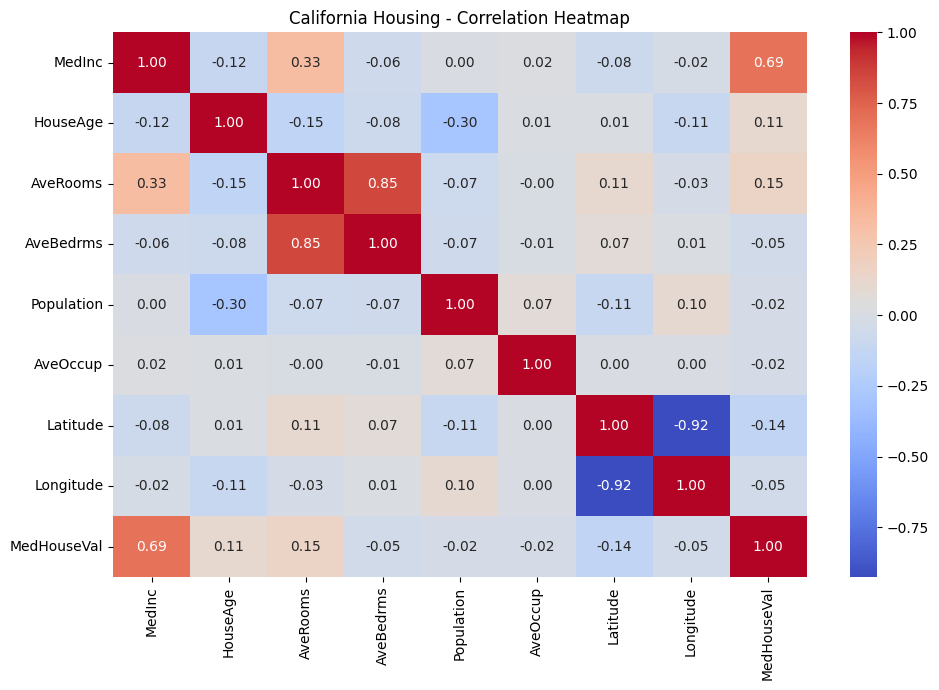

Interaction features created successfully!
Updated dataset shape: (20640, 12)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal,RoomsPerBedroom,IncomePerOccupant,Income_Age_Interaction
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526,6.821699,3.257686,341.3332
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585,6.418619,3.934606,174.3294
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521,7.721045,2.589837,377.3848
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413,5.421272,2.214764,293.4412
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422,5.810709,1.763125,200.0024


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Check missing values
print("Total missing values:", df.isnull().sum().sum())

# 2. Correlation heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(
    df.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)
plt.title("California Housing - Correlation Heatmap")
plt.tight_layout()
plt.show()

# 3. Create interaction features
df["RoomsPerBedroom"] = df["AveRooms"] / (df["AveBedrms"] + 1e-6)
df["IncomePerOccupant"] = df["MedInc"] / (df["AveOccup"] + 1e-6)
df["Income_Age_Interaction"] = df["MedInc"] * df["HouseAge"]

print("Interaction features created successfully!")
print("Updated dataset shape:", df.shape)

display(df.head())

In [ ]:
# TASK 2: CALIFORNIA HOUSING PRICE PREDICTION

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Load dataset
housing = fetch_california_housing(as_frame=True)
df = housing.frame.copy()

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())

Dataset loaded successfully!
Dataset shape: (20640, 9)
Columns: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [ ]:
# Create interaction features
df["RoomsPerBedroom"] = (
    df["AveRooms"] / (df["AveBedrms"] + 1e-6)
)

df["IncomePerOccupant"] = (
    df["MedInc"] / (df["AveOccup"] + 1e-6)
)

df["Income_Age_Interaction"] = (
    df["MedInc"] * df["HouseAge"]
)

print("Interaction features created!")
print("Updated dataset shape:", df.shape)

display(df.head())

Interaction features created!
Updated dataset shape: (20640, 12)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal,RoomsPerBedroom,IncomePerOccupant,Income_Age_Interaction
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526,6.821699,3.257686,341.3332
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585,6.418619,3.934606,174.3294
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521,7.721045,2.589837,377.3848
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413,5.421272,2.214764,293.4412
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422,5.810709,1.763125,200.0024


In [ ]:
# Target column
target = "MedHouseVal"

# Features and target
X = df.drop(columns=[target])
y = df[target]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Number of features:", X_train.shape[1])

Training samples: 16512
Testing samples: 4128
Number of features: 11


In [ ]:
# OLS Linear Regression
ols_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

ols_model.fit(X_train, y_train)
ols_pred = ols_model.predict(X_test)

print("OLS model trained successfully!")

OLS model trained successfully!
